In [23]:
# ==============================
# 1. IMPORT LIBRARIES
# ==============================
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

In [10]:
# ==============================
# 2. LOAD DATA
# ==============================
data = pd.read_csv("Assignment3-Breast-Cancer-Diagnose.csv")

# Drop ID column if exists
if 'id' in data.columns:
    data = data.drop(columns=['id'])

# Convert diagnosis column (M=1, B=0)
data['diagnosis'] = data['diagnosis'].map({'M':1, 'B':0})

# Quick look
data.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [11]:
# ==============================
# 3. HANDLE MISSING VALUES
# ==============================
# Fill numeric NaNs with column mean
data = data.fillna(data.mean())

# Check for any remaining missing values
print("Missing values per column:")
print(data.isna().sum())

Missing values per column:
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed: 32 

In [12]:
# ==============================
# 4. SPLIT FEATURES AND LABELS
# ==============================
X = data.drop(columns=['diagnosis'])
y = data['diagnosis']

In [13]:
# ==============================
# 5. TRAIN-TEST SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Training samples: 455, Test samples: 114


In [14]:
# ==============================
# 6. FEATURE SCALING
# ==============================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:1207: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:1212: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:1236: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [24]:
# SimpleImputer fills missing values
# StandardScaler scales features
log_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),  # Fill NaNs with mean
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Hyperparameter grid
param_log = {
    'classifier__C': [0.01, 0.1, 1, 10]
}

grid_log = GridSearchCV(log_pipeline, param_log, cv=5)
grid_log.fit(X_train, y_train)  # ✅ No more NaN error

print("Best Logistic Regression Params:", grid_log.best_params_)

/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarni

Best Logistic Regression Params: {'classifier__C': 1}


/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarni

In [25]:
knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier())
])

param_knn = {'classifier__n_neighbors': [3, 5, 7, 9]}
grid_knn = GridSearchCV(knn_pipeline, param_knn, cv=5)
grid_knn.fit(X_train, y_train)

print("Best KNN Params:", grid_knn.best_params_)

Best KNN Params: {'classifier__n_neighbors': 5}


/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarni

In [26]:
svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('classifier', SVC())
])

param_svm = {'classifier__C':[0.1, 1, 10], 'classifier__kernel':['linear','rbf']}
grid_svm = GridSearchCV(svm_pipeline, param_svm, cv=5)
grid_svm.fit(X_train, y_train)

print("Best SVM Params:", grid_svm.best_params_)

Best SVM Params: {'classifier__C': 0.1, 'classifier__kernel': 'linear'}


/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarni

In [27]:
def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"\n{name} Evaluation:")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-score: {f1:.4f}")
    
    return acc, prec, rec, f1

evaluate_model("Logistic Regression", grid_log.best_estimator_)
evaluate_model("KNN", grid_knn.best_estimator_)
evaluate_model("SVM", grid_svm.best_estimator_)


Logistic Regression Evaluation:
Accuracy: 0.9737
Precision: 0.9762
Recall: 0.9535
F1-score: 0.9647

KNN Evaluation:
Accuracy: 0.9474
Precision: 0.9302
Recall: 0.9302
F1-score: 0.9302

SVM Evaluation:
Accuracy: 0.9825
Precision: 1.0000
Recall: 0.9535
F1-score: 0.9762


/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


(0.9824561403508771, 1.0, 0.9534883720930233, 0.9761904761904762)

/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


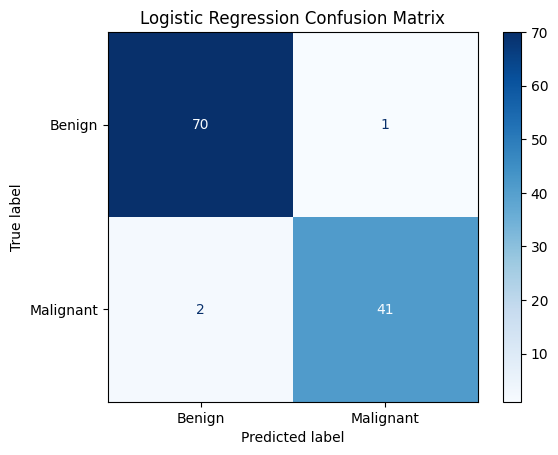

/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


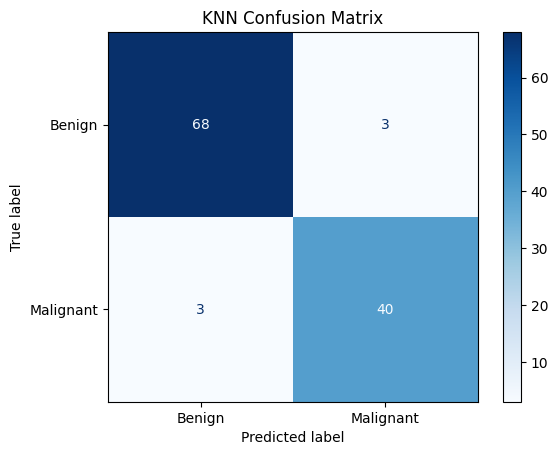

/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


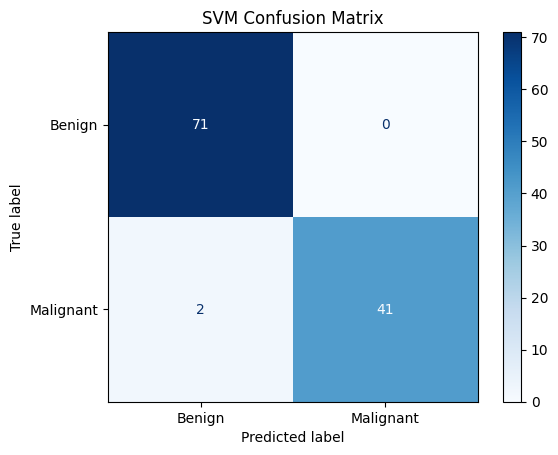

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# List of models
models = {
    "Logistic Regression": grid_log.best_estimator_,
    "KNN": grid_knn.best_estimator_,
    "SVM": grid_svm.best_estimator_
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Malignant'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"{name} Confusion Matrix")
    plt.show()


Logistic Regression Evaluation:
Accuracy: 0.9737
Precision: 0.9762
Recall: 0.9535
F1-score: 0.9647

KNN Evaluation:
Accuracy: 0.9474
Precision: 0.9302
Recall: 0.9302
F1-score: 0.9302

SVM Evaluation:
Accuracy: 0.9825
Precision: 1.0000
Recall: 0.9535
F1-score: 0.9762


/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/nicolelee/Downloads/coding project coursera/ASSIGNMENT 3/venv/lib/python3.14/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: [30]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


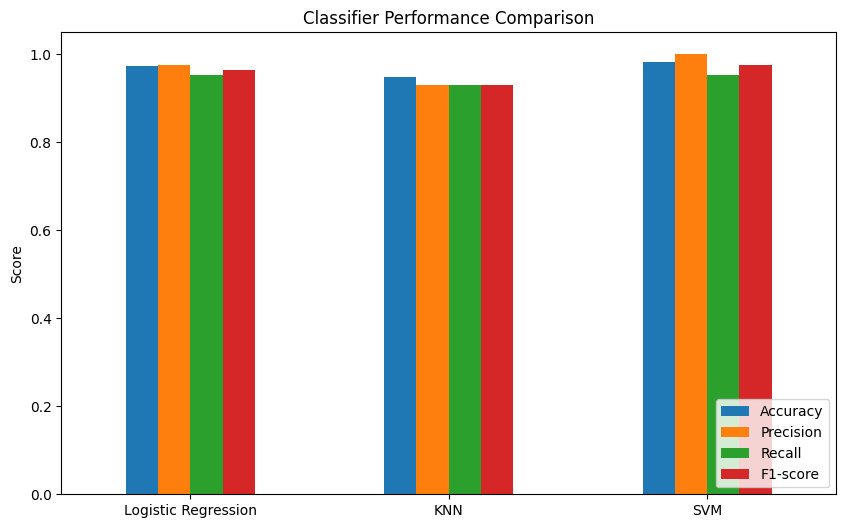

In [ ]:
# Collect metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results = {
    "Logistic Regression": evaluate_model("Logistic Regression", grid_log.best_estimator_),
    "KNN": evaluate_model("KNN", grid_knn.best_estimator_),
    "SVM": evaluate_model("SVM", grid_svm.best_estimator_)
}

import pandas as pd
results_df = pd.DataFrame(results, index=metrics)

# Plot
results_df.T.plot(kind='bar', figsize=(10,6))
plt.title("Classifier Performance Comparison")
plt.ylabel("Score")
plt.ylim(0,1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [ ]:
df.isnull().sum()